In [1]:
import numpy as np
import matplotlib.pyplot as plt
import os
from pathlib import Path
import pandas as pd

os.environ["CUDA_VISIBLE_DEVICES"] = "9"  # adjust for your machine and availability
import jax


from c3po.model.model import C3PO
from c3po.toy_model_generators.hmm import generate_hmm_spike_train
from c3po.toy_model_generators.phase import (
    generate_periodic_spike_train,
    generate_waveform_features,
)
from c3po.analysis.analysis import figure_directory

plt.rcParams["svg.fonttype"] = "none"  # to keep fonts editable in Illustrator

# Load Data

In [2]:
data_name = "periodic_toy_model_non_coding_units_v2"
data_dir = Path("/stelmo/sam/c3po_datasets") / data_name


spiking_df = pd.read_pickle(data_dir / "spiking_data.pkl")
neuron_df = pd.read_pickle(data_dir / "neuron_data.pkl")
metadata_df = pd.read_pickle(data_dir / "metadata.pkl")

mark_times = spiking_df["time"].values
mark_ids = spiking_df["unit"].values
marks = np.array(spiking_df["mark"].to_list())

t_max = metadata_df["t_max"].values[0]
latent_period = metadata_df["latent_period"].values[0]
noise_scale = metadata_df["noise_scale"].values[0]
n_units = metadata_df["n_units"].values[0]
n_channels = metadata_df["n_channels"].values[0]
max_wait_update = metadata_df["max_wait_update"].values[0]

template_waveforms = np.stack(neuron_df["template_waveform"].values)
tuning_curves = {
    "theta_max": neuron_df["theta_max"].values,
    "sigma": neuron_df["sigma"].values,
    "amplitude": neuron_df["amplitude"].values,
}

t = np.arange(0, t_max, 0.001)
theta = np.mod(t, latent_period) / latent_period * 2 * np.pi

In [3]:
n_noise_units = metadata_df["n_noise_units"].values[0]

# Load Results

In [4]:
from c3po.tables.dev_tables import C3POStorage

# model_tag = "model_8d"
model_tag = "model_16d"
model_name = f"{data_name}_{model_tag}"


key = {"model_name": model_name}
analysis = (C3POStorage & key).fetch_analysis_object()

analysis.load_embedding(f"/stelmo/sam/c3po_results/{key['model_name']}_embedding.npz")
context_dim = analysis.context_dim
latent_dim = analysis.latent_dim

t_interp = np.arange(analysis.t[0], analysis.t[-1], 0.001)
analysis.interpolate_context(t_interp)
analysis.fit_context_pca(interpolated=True)

# # Just showing how to access the variables
# t = analysis.t
# z = analysis.z
# c = analysis.c
# c_pca = analysis.c_pca
# t_interp = analysis.t_interp
# c_interp = analysis.c_interp
# c_pca_interp = analysis.c_pca_interp
# latent_dim, context_dim = analysis.latent_dim, analysis.context_dim

# define figure directory
from c3po.analysis.analysis import figure_directory
from pathlib import Path

figure_directory = Path(figure_directory)
figure_folder = figure_directory / "Fig_1" / model_name
os.makedirs(figure_folder, exist_ok=True)

/home/sambray/.local/lib/python3.10/site-packages/datajoint/plugin.py:4: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources  # requires setuptools<82
[2026-10-29 11:37:26,878][INFO]: DataJoint 0.14.9 connected to sambray@lmf-db.cin.ucsf.edu:3306
2026-10-29 11:37:30.246253: W external/xla/xla/service/gpu/autotuning/dot_search_space.cc:200] All configs were filtered out because none of them sufficiently match the hints. Maybe the hints set does not contain a good representative set of valid configs?Working around this by using the full hints set instead.
2026-10-29 11:37:31.468737: W external/xla/xla/service/gpu/autotuning/dot_search_space.cc:200] All configs were filtered out because none of them sufficiently match the hints. Maybe the hints set does not contain a good represe

# Analyze

## Observed and modeled rates

In [6]:
spiking_df

,time,unit,mark
0,0.009309,55,"[-0.2799293773951622, 0.0747189574666303, -0.1..."
1,0.086806,58,"[-0.006836872918396003, -0.04195643868957932, ..."
2,0.151985,10,"[0.11731052942024112, 0.10366956582830528, 0.0..."
3,0.162465,42,"[-0.1159473210359941, 0.17174913555659507, -0...."
4,0.231048,42,"[-0.07303813400387528, 0.07539515878878503, 0...."
...,...,...,...
246493,4999.982997,18,"[0.19717341233264882, 0.07756171621194478, 0.0..."
246494,4999.983963,34,"[0.1196268610373552, 0.011179596935128499, -0...."
246495,4999.993398,58,"[-0.0032444256178727447, -0.07403407002868449,..."
246496,4999.995001,53,"[-0.007152414668831414, 0.03801563614815837, -..."


In [31]:
t_spikes = np.arange(t[0], t[-1], 0.002)
spikes = []
# for uu in range(len(units["mec"][0]["spikeTimes"])):
#     spikes.append(units["mec"][0]["spikeTimes"][uu][0].flatten())

# len(spikes)

for uu in np.arange(n_units):
    spikes.append(spiking_df[spiking_df.unit == uu].time.values)

from scipy.ndimage import gaussian_filter1d
from tqdm import tqdm

smoothing_window = 0.05  # in seconds
# smoothing_window = 0.003  # in seconds
dt = t_spikes[1] - t_spikes[0]
smoothing_window_bins = int(smoothing_window / dt)
rates = []

for uu in tqdm(range(len(spikes))):
    rate, _ = np.histogram(
        spikes[uu], bins=np.concatenate([t_spikes, [t_spikes[-1] + (dt)]])
    )
    # rate = np.convolve(
    #     rate,
    #     np.ones(smoothing_window_bins) / smoothing_window_bins,
    #     mode="same",
    # )
    rate = gaussian_filter1d(
        rate[:, None].astype("float"),
        sigma=smoothing_window_bins,
        axis=0,
        mode="nearest",
    )

    rates.append(rate / (t_spikes[1] - t_spikes[0]))  # in Hz
rates = np.squeeze(rates).T
mua = rates.sum(axis=1)

100%|██████████| 64/64 [00:18<00:00,  3.39it/s]


In [66]:
# True rates

true_rates = np.zeros_like(rates)
theta_t_spike = theta[np.digitize(t_spikes, t)]
from c3po.toy_model_generators.phase import firing_rate
for i in tqdm(range(rates.shape[1])):
    tuning_curve_i = firing_rate(
        theta_t_spike,
        tuning_curves["theta_max"][i],
        tuning_curves["sigma"][i],
        tuning_curves["amplitude"][i],
    )
    if i >(64-16): # non-tuned neurons
        tuning_curve_i = np.mean(tuning_curve_i)

    true_rates[:,i] = tuning_curve_i

100%|██████████| 64/64 [00:02<00:00, 31.11it/s]


## C3po Inferered rates

In [33]:
z_neuron = []
for neuron_i in range(n_units):
    i_ = neuron_i
    ind_marks = np.where(mark_ids[1:] == neuron_i)[0]

    pc_componenents = analysis.pca.components_
    z_neuron_i = analysis.z[ind_marks].copy()

    z_mean = np.nanmean(z_neuron_i, axis=0)

    z_neuron.append(z_mean)
z_neuron = np.array(z_neuron)

In [52]:
c = analysis.c
# z_neuron =analysis.params['params']['embedding']['encoder']['encoder_matrix']
t_ = analysis.t
delta_t = np.concatenate([np.array([1]), np.diff(t_)])
delta_t = gaussian_filter1d(
    delta_t[:, None],
    sigma=1,
    axis=0,
    mode="nearest",
)[:,0]
big_lam = 1/delta_t

cum_spikes = rates.mean(axis=0)
gamma = cum_spikes / np.sum(cum_spikes)

cz = np.dot(c, z_neuron.T)
zz = np.sum(z_neuron**2, axis=1)

cz.shape, zz.shape

from scipy.special import logsumexp
exponent = cz+zz[None,:]+np.log(gamma[None,:])
log_alpha = logsumexp(exponent, axis=1)

log_lam = np.log(big_lam[:, None]) + np.log(gamma[None,:]) - log_alpha[:, None] + cz + zz[None,:]

## Plot

Text(0.5, 1.0, 'Neuron 60 (noise)')

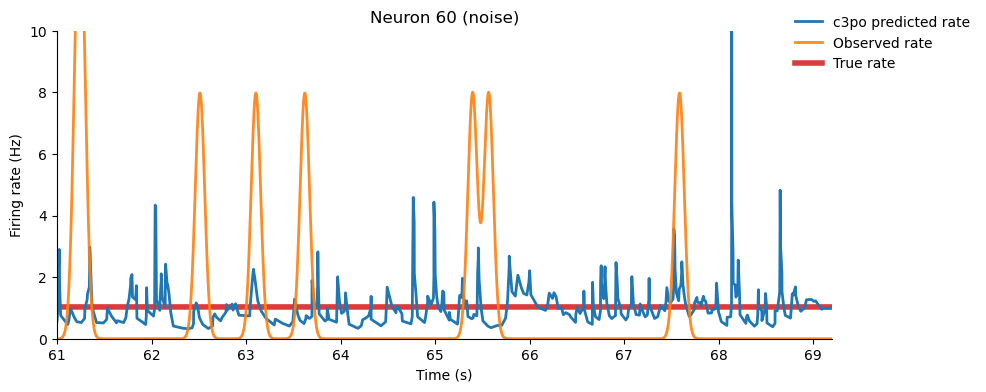

In [76]:
i = 60
# i = 230

st = 301500
ind = slice(st, st + 6000)
st = 3000 +50#0*200
ind = slice(st, st + 400)

t_st = analysis.t[ind][0]
t_end = analysis.t[ind][-1]

ind_rate = np.where(np.logical_and(t_spikes>t_st, t_spikes<t_end))[0]

fig, ax = plt.subplots(figsize=(10, 4))


# ax2 = ax.twinx()
# ax.set_zorder(2)
# ax.patch.set_visible(False)
# ax2.plot(t_spikes[ind_rate], mua[ind_rate,], label=f"mua", color="grey",zorder=-1)
# ax2.plot(analysis.t[ind], 1/delta_t[ind], label=f"1/delta_t", color="red",zorder=-1)

c1 = "C0"
c2 = "C1"
c3 = "C3"
ax.plot(analysis.t[ind], np.exp(log_lam[ind,i]), label="c3po predicted rate", color=c1,lw=2)
ax.plot(t_spikes[ind_rate], rates[ind_rate, i], label=f"Observed rate", color=c2, alpha=.9,lw=2)
ax.plot(t_spikes[ind_rate], true_rates[ind_rate, i], label=f"True rate", color=c3, alpha=.9,lw=4, zorder=-2)
lim = np.max(true_rates[ind_rate, i])*2
lim = max(lim, 10)
ax.set_ylim(0, lim)

fig.legend(bbox_to_anchor=(.85, 0.95), loc="upper left", frameon=False)
ax.set_ylabel("Firing rate (Hz)")
ax.set_xlim(t_st, t_end)
ax.spines[["top", "right"]].set_visible(False)
ax.set_xlabel("Time (s)")

title = f"Neuron {i}"
if i > (64-16):
    title += " (noise)"
ax.set_title(title)
# ax2 = ax.twinx()
# ax2.set_ylabel("MUA (Hz)")